# DS-471 Project: Breast Cancer Classification (WDBC)

Benign vs. malignant tumor classification with Logistic Regression, SVM, Random Forest and a Neural Network (MLP). Malignant = positive class (1).

**Colab:** run the setup cell, upload `wdbc_clean.csv` when asked, then *Runtime → Run all*.

## Setup: imports, helper functions

In [1]:
import warnings
from copy import deepcopy
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, log_loss, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
POSITIVE_LABEL = 1  # Malignant
sns.set_theme(style="whitegrid")
output_dir = Path("figures"); output_dir.mkdir(exist_ok=True)
tables_dir = Path("results"); tables_dir.mkdir(exist_ok=True)


def locate_dataset():
    """Find wdbc_clean.csv; in Google Colab, ask the user to upload it."""
    for p in [Path("wdbc_clean.csv"), Path("data/wdbc_clean.csv"), Path("/content/wdbc_clean.csv")]:
        if p.exists():
            return p
    try:
        from google.colab import files
        print("Please upload wdbc_clean.csv")
        files.upload()
        return Path("wdbc_clean.csv")
    except ImportError:
        raise FileNotFoundError("Place wdbc_clean.csv beside this notebook or in ./data")


In [2]:
def metric_row(name, y_true, y_pred, y_score):
    """Return classification metrics with malignant as the positive class."""
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label=POSITIVE_LABEL, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label=POSITIVE_LABEL, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, pos_label=POSITIVE_LABEL, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
    }


def evaluate_model(model, X, y):
    """Return labels and malignant probabilities for a fitted estimator."""
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]
    return predictions, probabilities


class ScaledMLP:
    """Apply the fitted scaler before using the saved MLP checkpoint."""

    def __init__(self, scaler, model):
        self.scaler = scaler
        self.model = model

    def predict(self, X):
        return self.model.predict(self.scaler.transform(X))

    def predict_proba(self, X):
        return self.model.predict_proba(self.scaler.transform(X))


def save_figure(path):
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

## Stage 1: Data loading, cleaning and target encoding

We load the file, check for missing values and duplicates, remove the `id` column because it is only an identifier, and change the labels to numbers (Benign = 0, Malignant = 1).

In [3]:
# Stage 1: load the selected UCI dataset and prepare the target.
csv_path = locate_dataset()
raw_df = pd.read_csv(csv_path)
required_columns = {"id", "diagnosis"}
missing_columns = required_columns.difference(raw_df.columns)
if missing_columns:
    raise ValueError(f"The CSV is missing required columns: {missing_columns}")

duplicate_count = raw_df.drop(columns=["id"]).duplicated().sum()
missing_count = raw_df.isna().sum().sum()
print(f"Dataset file: {csv_path}")
print(f"Original dataset shape: {raw_df.shape}")
print(f"Missing values: {missing_count}")
print(f"Duplicate records excluding ID: {duplicate_count}")
print("Diagnosis counts in source file:")
print(raw_df["diagnosis"].value_counts().sort_index())

if missing_count:
    raise ValueError("The dataset contains missing values; handle them before modeling.")
if duplicate_count:
    raise ValueError("Duplicate records were found; review them before modeling.")

df = raw_df.drop(columns=["id"]).copy()
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})
if df["diagnosis"].isna().any():
    raise ValueError("Unexpected diagnosis labels. Expected only B and M.")
df["diagnosis"] = df["diagnosis"].astype(int)

X = df.drop(columns="diagnosis")
y = df["diagnosis"]
print(f"Working dataset shape (ID excluded): {df.shape}")
print("Encoded target counts (0=Benign, 1=Malignant):")
print(y.value_counts().sort_index())
print("\nFeature data types:")
print(X.dtypes.value_counts())

Please upload wdbc_clean.csv


Saving wdbc_clean.csv to wdbc_clean.csv
Dataset file: wdbc_clean.csv
Original dataset shape: (569, 32)
Missing values: 0
Duplicate records excluding ID: 0
Diagnosis counts in source file:
diagnosis
B    357
M    212
Name: count, dtype: int64
Working dataset shape (ID excluded): (569, 31)
Encoded target counts (0=Benign, 1=Malignant):
diagnosis
0    357
1    212
Name: count, dtype: int64

Feature data types:
float64    30
Name: count, dtype: int64


## Stage 2: Data splitting (70% train / 15% validation / 15% test, stratified)

We split the data into 70% training, 15% validation and 15% test, using stratified sampling so that each part has a similar share of benign and malignant cases. We do the split before the EDA so that the test set does not influence our decisions.

In [4]:
# Split before target-informed EDA so that test data do not guide analysis.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE,
    stratify=y_temp
)
split_summary = pd.DataFrame([
    {"Dataset": "Training", "Samples": len(y_train),
     "Benign": int((y_train == 0).sum()), "Malignant": int((y_train == 1).sum())},
    {"Dataset": "Validation", "Samples": len(y_val),
     "Benign": int((y_val == 0).sum()), "Malignant": int((y_val == 1).sum())},
    {"Dataset": "Testing", "Samples": len(y_test),
     "Benign": int((y_test == 0).sum()), "Malignant": int((y_test == 1).sum())},
])
split_summary.to_csv(tables_dir / "data_split.csv", index=False)
print("\nData split:")
print(split_summary.to_string(index=False))


Data split:
   Dataset  Samples  Benign  Malignant
  Training      398     250        148
Validation       85      53         32
   Testing       86      54         32


## Stage 1 (continued): Outliers

We used the IQR rule to find possible outliers in the training data. We decided to keep them, because extreme values in medical measurements may be real and not mistakes.

Training rows with at least one potential outlier: 119
Decision: retain potential outliers because they may represent valid measurements.


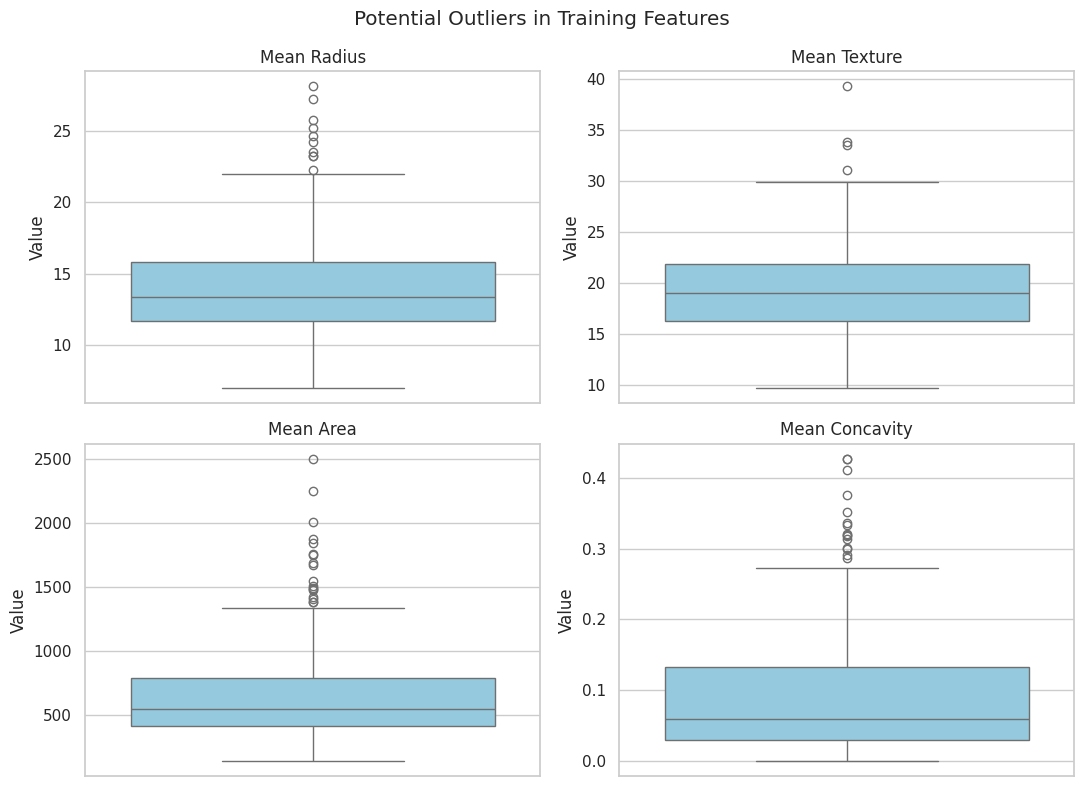

In [5]:
# Outlier review uses training features. Potential outliers are retained.
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outlier_mask = (X_train < (q1 - 1.5 * iqr)) | (X_train > (q3 + 1.5 * iqr))
outlier_counts = outlier_mask.sum().sort_values(ascending=False)
outlier_counts.rename("Potential outliers").to_csv(
    tables_dir / "outlier_counts_training.csv"
)
print(f"Training rows with at least one potential outlier: {outlier_mask.any(axis=1).sum()}")
print("Decision: retain potential outliers because they may represent valid measurements.")

selected_features = ["mean_radius", "mean_texture", "mean_area", "mean_concavity"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feature in zip(axes.flat, selected_features):
    sns.boxplot(y=X_train[feature], color="skyblue", ax=ax)
    ax.set_title(feature.replace("_", " ").title())
    ax.set_ylabel("Value")
fig.suptitle("Potential Outliers in Training Features")
save_figure(output_dir / "01_outlier_boxplots.png")

## Stage 1 (continued): Exploratory data analysis

Here we look at the target distribution, the feature distributions for each diagnosis, and the correlations between features. All plots use the training set only.

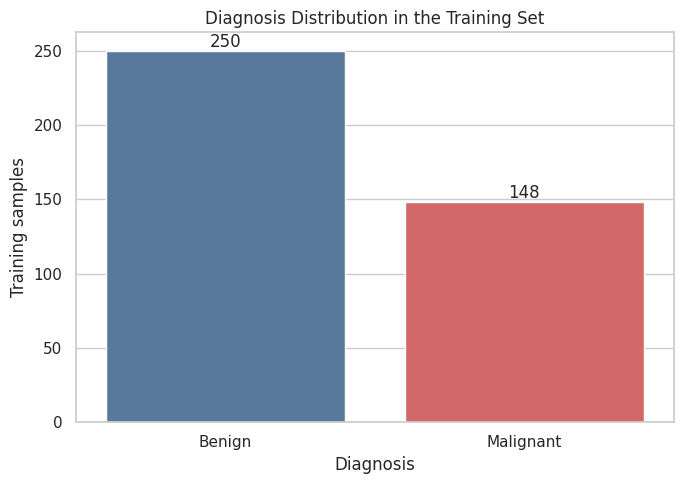

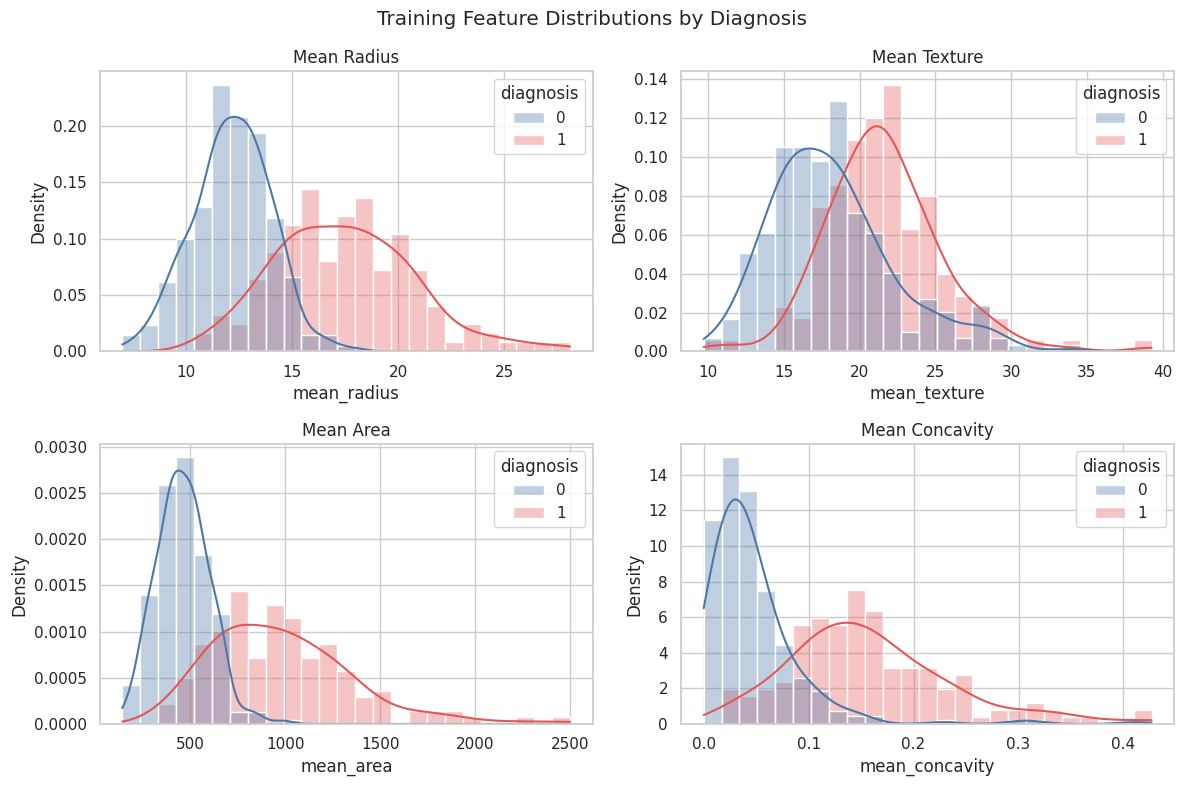

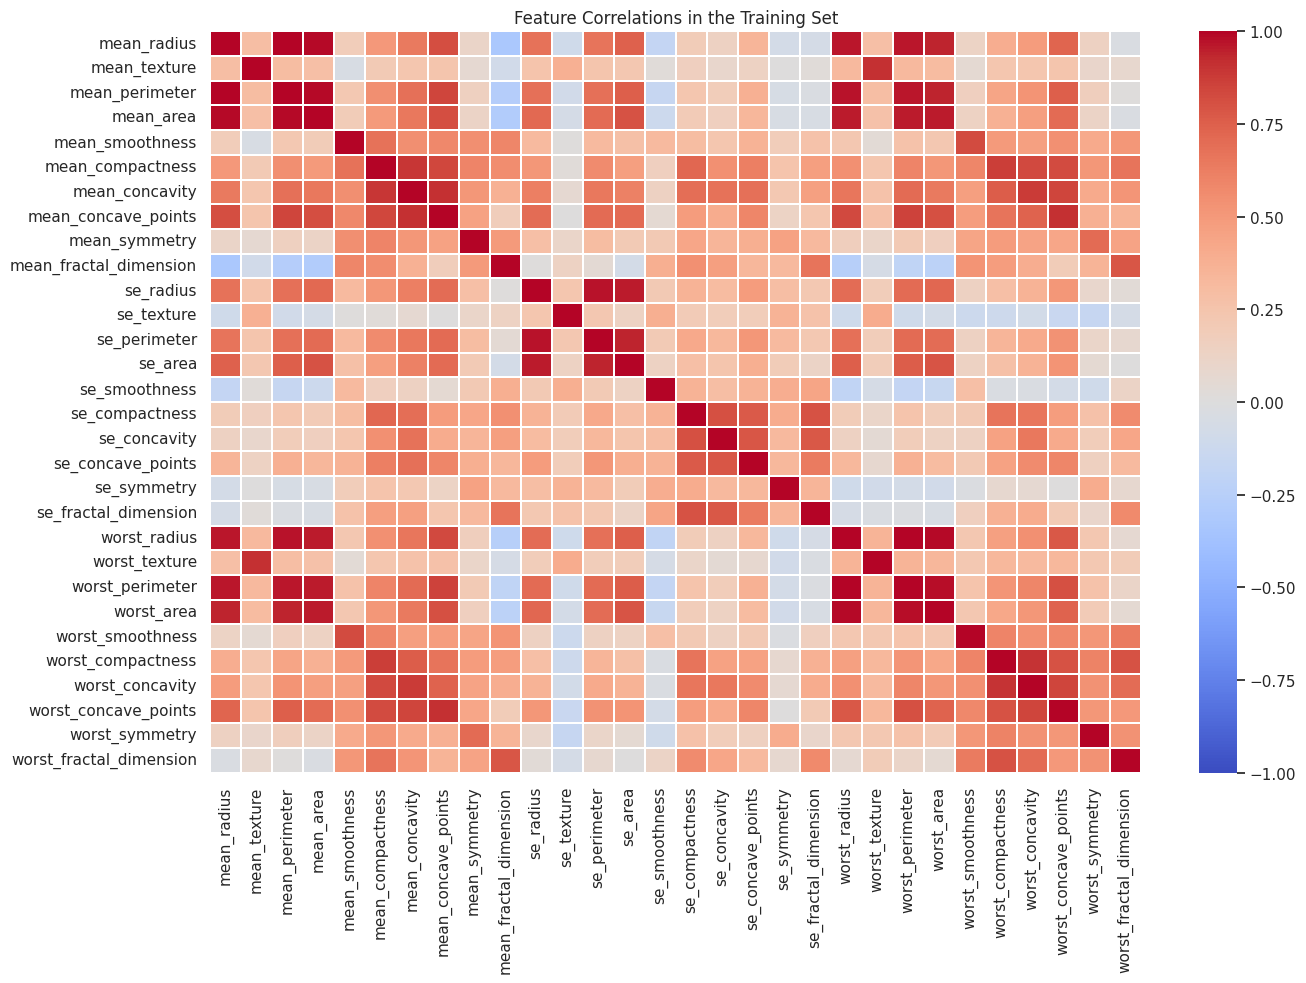

In [6]:
train_eda = X_train.copy()
train_eda["diagnosis"] = y_train
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=train_eda, x="diagnosis", hue="diagnosis",
              order=[0, 1], palette={0: "#4C78A8", 1: "#E45756"},
              legend=False, ax=ax)
ax.set_xticks([0, 1], ["Benign", "Malignant"])
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Training samples")
ax.set_title("Diagnosis Distribution in the Training Set")
for container in ax.containers:
    ax.bar_label(container)
save_figure(output_dir / "02_training_target_distribution.png")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, selected_features):
    sns.histplot(data=train_eda, x=feature, hue="diagnosis",
                 hue_order=[0, 1], bins=25, stat="density",
                 common_norm=False, kde=True,
                 palette={0: "#4C78A8", 1: "#E45756"},
                 alpha=0.35, ax=ax)
    ax.set_title(feature.replace("_", " ").title())
fig.suptitle("Training Feature Distributions by Diagnosis")
save_figure(output_dir / "03_training_feature_distributions.png")

plt.figure(figsize=(14, 10))
sns.heatmap(X_train.corr(), cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.2)
plt.title("Feature Correlations in the Training Set")
save_figure(output_dir / "04_training_correlation_heatmap.png")

## Stage 1 (continued): Important features

We used Mutual Information on the training set to see which features are most related to the diagnosis.

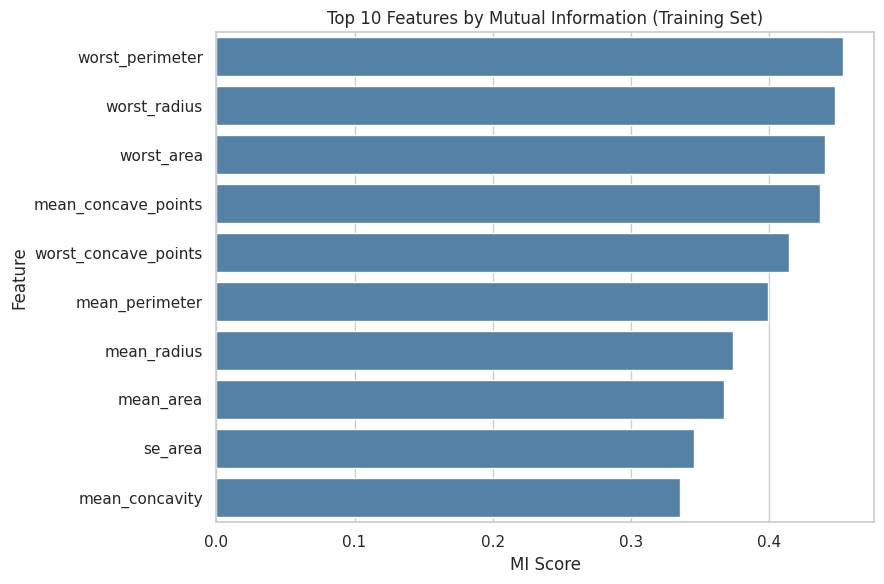


Top 10 features by mutual information:
             Feature  MI Score
     worst_perimeter  0.453002
        worst_radius  0.447489
          worst_area  0.440089
 mean_concave_points  0.436432
worst_concave_points  0.414030
      mean_perimeter  0.398869
         mean_radius  0.373748
           mean_area  0.367107
             se_area  0.345463
      mean_concavity  0.335188


In [7]:
# Mutual information is calculated on the training data only.
mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
feature_importance = pd.DataFrame({"Feature": X_train.columns, "MI Score": mi})
feature_importance = feature_importance.sort_values("MI Score", ascending=False)
feature_importance.to_csv(tables_dir / "mutual_information.csv", index=False)
plt.figure(figsize=(9, 6))
sns.barplot(data=feature_importance.head(10), x="MI Score", y="Feature",
            color="steelblue")
plt.title("Top 10 Features by Mutual Information (Training Set)")
save_figure(output_dir / "05_mutual_information_top10.png")
print("\nTop 10 features by mutual information:")
print(feature_importance.head(10).to_string(index=False))

## Stage 1 (continued): Encoding, feature engineering and scaling

- **Encoding:** all 30 features are numbers, so only the target needed encoding (B = 0, M = 1).
- **Feature engineering:** we did not create new features because the dataset already has detailed measurements of the cell nuclei.
- **Feature selection:** we kept all 30 features. Mutual Information looks at each feature alone, so it does not tell us which group of features works best together.
- **Correlated features:** radius, perimeter and area are strongly correlated. Logistic Regression and the neural network use L2 regularization, and Random Forest is not affected much by this.
- **Scaling:** we used StandardScaler for Logistic Regression, SVM and the Neural Network because they are sensitive to the scale of the features. We put it inside a Pipeline so it is fitted only on training data. Random Forest does not need scaling.
- **Outliers:** kept, as explained above

## Stage 3: Choosing the models

We chose Logistic Regression (simple linear baseline), SVM with an RBF kernel (can learn non-linear boundaries), Random Forest (ensemble of trees), and a Neural Network (MLP, one hidden layer with 32 ReLU neurons), which is required by the project.

In [8]:
# Stage 3: define the required neural network and three traditional models.
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Neural Network": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(32,), activation="relu",
            max_iter=1000, random_state=RANDOM_STATE)),
    ]),
}

## Stage 4: Baseline training and validation

First we train all four models with simple settings and compare training and validation scores to see if there is overfitting.

In [9]:
# Stage 4: baseline results on training and validation sets.
baseline_rows = []
for name, model in models.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(X_train, y_train)
    train_pred, train_score = evaluate_model(model, X_train, y_train)
    val_pred, val_score = evaluate_model(model, X_val, y_val)
    baseline_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Train F1": f1_score(y_train, train_pred, zero_division=0),
        "Validation F1": f1_score(y_val, val_pred, zero_division=0),
        "Validation Malignant Recall": recall_score(y_val, val_pred, zero_division=0),
        "Validation ROC-AUC": roc_auc_score(y_val, val_score),
    })
baseline_results = pd.DataFrame(baseline_rows)
baseline_results.to_csv(tables_dir / "baseline_validation_results.csv", index=False)
print("\nBaseline performance:")
print(baseline_results.round(4).to_string(index=False))


Baseline performance:
                 Model  Train Accuracy  Validation Accuracy  Train F1  Validation F1  Validation Malignant Recall  Validation ROC-AUC
   Logistic Regression          0.9874               0.9647    0.9828         0.9508                       0.9062              0.9965
Support Vector Machine          0.9849               0.9529    0.9793         0.9333                       0.8750              0.9959
         Random Forest          1.0000               0.9647    1.0000         0.9508                       0.9062              0.9941
        Neural Network          0.9925               0.9647    0.9898         0.9508                       0.9062              0.9935


## Stage 4: Hyperparameter tuning

We used GridSearchCV with 5-fold stratified cross-validation on the training set only. We used F1-score to choose the best parameters because the classes are not perfectly balanced and missing a malignant case is serious.

In [10]:
# Hyperparameter search runs only on training data; scaling is inside pipelines.
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__solver": ["lbfgs", "liblinear"],
    },
    "Support Vector Machine": {
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", "auto", 0.01, 0.001],
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10, 15],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
    },
    "Neural Network": {
        "model__hidden_layer_sizes": [(32,), (64,), (32, 16), (64, 32)],
        "model__alpha": [0.0001, 0.001, 0.01, 0.1],
        "model__learning_rate_init": [0.001, 0.01],
    },
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuned_models = {}
tuning_rows = []
for name, model in models.items():
    print(f"\nTuning {name}...")
    search = GridSearchCV(
        estimator=clone(model),
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": str(search.best_params_),
    })
tuning_results = pd.DataFrame(tuning_rows)
tuning_results.to_csv(tables_dir / "hyperparameter_search.csv", index=False)
print("\nBest hyperparameters from training-set cross-validation:")
print(tuning_results.to_string(index=False))


Tuning Logistic Regression...

Tuning Support Vector Machine...

Tuning Random Forest...

Tuning Neural Network...

Best hyperparameters from training-set cross-validation:
                 Model  Best CV F1                                                                                 Best Parameters
   Logistic Regression    0.975672                                                       {'model__C': 1, 'model__solver': 'lbfgs'}
Support Vector Machine    0.964596                                                           {'model__C': 1, 'model__gamma': 0.01}
         Random Forest    0.928206         {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
        Neural Network    0.968991 {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64,), 'model__learning_rate_init': 0.01}


### Tuned models on training vs. validation

In [11]:
tuned_validation_rows = []
for name, model in tuned_models.items():
    train_pred, _ = evaluate_model(model, X_train, y_train)
    val_pred, val_score = evaluate_model(model, X_val, y_val)
    tuned_validation_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Train F1": f1_score(y_train, train_pred, zero_division=0),
        "Validation F1": f1_score(y_val, val_pred, zero_division=0),
        "Validation Malignant Recall": recall_score(y_val, val_pred, zero_division=0),
        "Validation ROC-AUC": roc_auc_score(y_val, val_score),
    })
tuned_validation = pd.DataFrame(tuned_validation_rows)
tuned_validation.to_csv(tables_dir / "tuned_validation_results.csv", index=False)
print("\nTuned model validation results:")
print(tuned_validation.round(4).to_string(index=False))


Tuned model validation results:
                 Model  Train Accuracy  Validation Accuracy  Train F1  Validation F1  Validation Malignant Recall  Validation ROC-AUC
   Logistic Regression          0.9874               0.9647    0.9828         0.9508                       0.9062              0.9965
Support Vector Machine          0.9774               0.9529    0.9686         0.9333                       0.8750              0.9965
         Random Forest          1.0000               0.9647    1.0000         0.9508                       0.9062              0.9929
        Neural Network          1.0000               0.9647    1.0000         0.9508                       0.9062              0.9882


### Neural Network curves before fixing overfitting

These curves show the loss and accuracy of the tuned network at each epoch. The training loss keeps going down, but the validation loss starts to go up after about epoch 11, which means the network is overfitting.

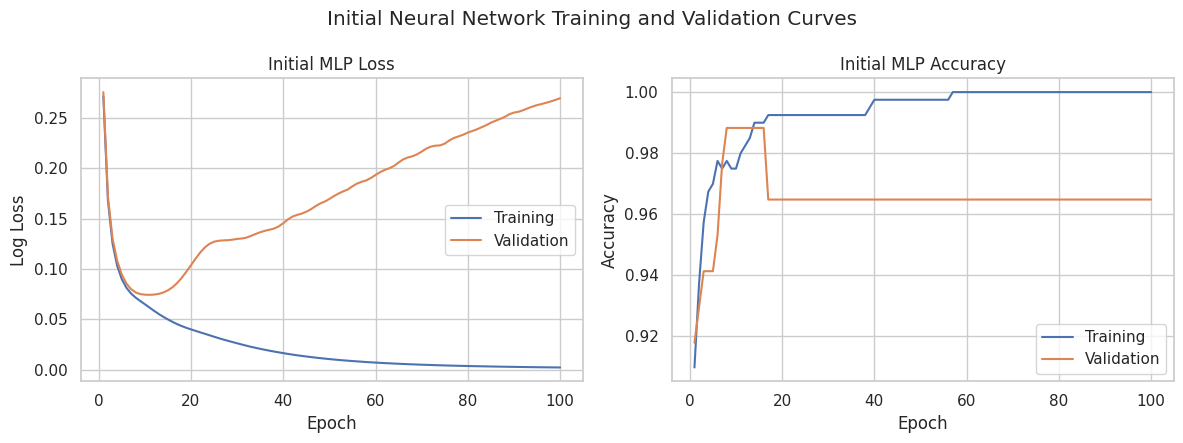

In [12]:
# Plot learning curves for the selected initial MLP configuration.
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
initial_mlp = MLPClassifier(
    hidden_layer_sizes=(64,), activation="relu", solver="adam",
    alpha=0.0001, learning_rate_init=0.01, max_iter=1,
    random_state=RANDOM_STATE,
)
initial_history = {"epoch": [], "train_loss": [], "val_loss": [],
                   "train_accuracy": [], "val_accuracy": []}
for epoch in range(1, 101):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if epoch == 1:
            initial_mlp.partial_fit(X_train_scaled, y_train, classes=np.array([0, 1]))
        else:
            initial_mlp.partial_fit(X_train_scaled, y_train)
    train_prob = initial_mlp.predict_proba(X_train_scaled)
    val_prob = initial_mlp.predict_proba(X_val_scaled)
    initial_history["epoch"].append(epoch)
    initial_history["train_loss"].append(log_loss(y_train, train_prob, labels=[0, 1]))
    initial_history["val_loss"].append(log_loss(y_val, val_prob, labels=[0, 1]))
    initial_history["train_accuracy"].append(
        accuracy_score(y_train, initial_mlp.predict(X_train_scaled))
    )
    initial_history["val_accuracy"].append(
        accuracy_score(y_val, initial_mlp.predict(X_val_scaled))
    )
pd.DataFrame(initial_history).to_csv(tables_dir / "initial_mlp_history.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(initial_history["epoch"], initial_history["train_loss"], label="Training")
axes[0].plot(initial_history["epoch"], initial_history["val_loss"], label="Validation")
axes[0].set(title="Initial MLP Loss", xlabel="Epoch", ylabel="Log Loss")
axes[0].legend()
axes[1].plot(initial_history["epoch"], initial_history["train_accuracy"], label="Training")
axes[1].plot(initial_history["epoch"], initial_history["val_accuracy"], label="Validation")
axes[1].set(title="Initial MLP Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
fig.suptitle("Initial Neural Network Training and Validation Curves")
save_figure(output_dir / "06_initial_mlp_curves.png")

### Neural Network after regularization and early stopping

To reduce overfitting we used a stronger L2 penalty (alpha = 1.0), a smaller network (32 neurons), a lower learning rate (0.003), and early stopping based on the validation loss. We keep the weights from the epoch with the lowest validation loss.


Regularized MLP best epoch: 85
Early stopping occurred at epoch: 100


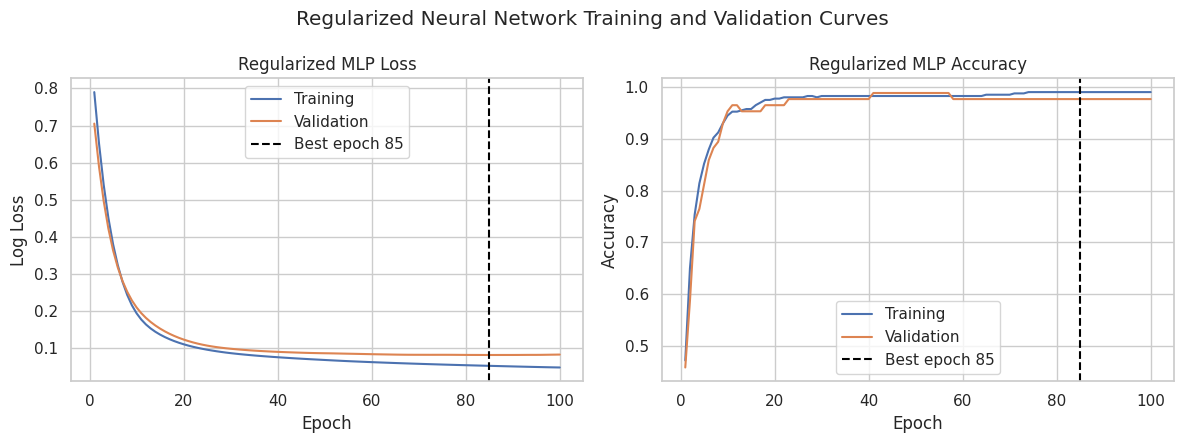

In [13]:
# Train a smaller, more strongly regularized MLP and apply early stopping
# using validation log loss. The test set is not used in this process.
final_mlp = MLPClassifier(
    hidden_layer_sizes=(32,), activation="relu", solver="adam",
    alpha=1.0, learning_rate_init=0.003, max_iter=1,
    random_state=RANDOM_STATE,
)
regularized_history = {"epoch": [], "train_loss": [], "val_loss": [],
                       "train_accuracy": [], "val_accuracy": []}
best_loss = np.inf
best_epoch = 0
best_model = None
patience = 15
epochs_without_improvement = 0
for epoch in range(1, 101):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if epoch == 1:
            final_mlp.partial_fit(X_train_scaled, y_train, classes=np.array([0, 1]))
        else:
            final_mlp.partial_fit(X_train_scaled, y_train)
    train_prob = final_mlp.predict_proba(X_train_scaled)
    val_prob = final_mlp.predict_proba(X_val_scaled)
    train_loss = log_loss(y_train, train_prob, labels=[0, 1])
    val_loss = log_loss(y_val, val_prob, labels=[0, 1])
    regularized_history["epoch"].append(epoch)
    regularized_history["train_loss"].append(train_loss)
    regularized_history["val_loss"].append(val_loss)
    regularized_history["train_accuracy"].append(
        accuracy_score(y_train, final_mlp.predict(X_train_scaled))
    )
    regularized_history["val_accuracy"].append(
        accuracy_score(y_val, final_mlp.predict(X_val_scaled))
    )
    if val_loss < best_loss:
        best_loss = val_loss
        best_epoch = epoch
        best_model = deepcopy(final_mlp)
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= patience:
        break
pd.DataFrame(regularized_history).to_csv(
    tables_dir / "regularized_mlp_history.csv", index=False
)
print(f"\nRegularized MLP best epoch: {best_epoch}")
print(f"Early stopping occurred at epoch: {regularized_history['epoch'][-1]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(regularized_history["epoch"], regularized_history["train_loss"], label="Training")
axes[0].plot(regularized_history["epoch"], regularized_history["val_loss"], label="Validation")
axes[0].axvline(best_epoch, color="black", linestyle="--", label=f"Best epoch {best_epoch}")
axes[0].set(title="Regularized MLP Loss", xlabel="Epoch", ylabel="Log Loss")
axes[0].legend()
axes[1].plot(regularized_history["epoch"], regularized_history["train_accuracy"], label="Training")
axes[1].plot(regularized_history["epoch"], regularized_history["val_accuracy"], label="Validation")
axes[1].axvline(best_epoch, color="black", linestyle="--", label=f"Best epoch {best_epoch}")
axes[1].set(title="Regularized MLP Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
fig.suptitle("Regularized Neural Network Training and Validation Curves")
save_figure(output_dir / "07_regularized_mlp_curves.png")

### Final models and validation results

The three traditional models use their best cross-validation settings, and the neural network is the regularized version. We compare them on the validation set before touching the test set.

In [14]:
# Select among models using validation performance, not test results.
# The regularized MLP replaces the grid-searched MLP after validation-based
# overfitting analysis; the other three models retain their best CV models.
final_models = {
    "Logistic Regression": tuned_models["Logistic Regression"],
    "Support Vector Machine": tuned_models["Support Vector Machine"],
    "Random Forest": tuned_models["Random Forest"],
    "Neural Network (Regularized MLP)": ScaledMLP(scaler, best_model),
}
# The scaler and MLP are already fitted on training data. The adapter keeps
# the best early-stopping checkpoint without fitting it a second time.

final_validation_rows = []
for name, model in final_models.items():
    val_pred, val_score = evaluate_model(model, X_val, y_val)
    final_validation_rows.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Validation Precision": precision_score(y_val, val_pred, zero_division=0),
        "Validation Malignant Recall": recall_score(y_val, val_pred, zero_division=0),
        "Validation F1": f1_score(y_val, val_pred, zero_division=0),
        "Validation ROC-AUC": roc_auc_score(y_val, val_score),
    })
final_validation = pd.DataFrame(final_validation_rows)
final_validation.to_csv(tables_dir / "final_validation_results.csv", index=False)
print("\nFinal model validation results (used for model selection):")
print(final_validation.round(4).to_string(index=False))


Final model validation results (used for model selection):
                           Model  Validation Accuracy  Validation Precision  Validation Malignant Recall  Validation F1  Validation ROC-AUC
             Logistic Regression               0.9647                   1.0                       0.9062         0.9508              0.9965
          Support Vector Machine               0.9529                   1.0                       0.8750         0.9333              0.9965
                   Random Forest               0.9647                   1.0                       0.9062         0.9508              0.9929
Neural Network (Regularized MLP)               0.9765                   1.0                       0.9375         0.9677              0.9959


## Stage 5: Final evaluation on the test set

Now we test each final model once on the test set and report accuracy, precision, recall, F1-score, ROC-AUC and the confusion matrix counts.

In [15]:
# Stage 5: evaluate the fixed model configurations on the test set.
test_rows = []
test_predictions = {}
test_scores = {}
for name, model in final_models.items():
    predictions, scores = evaluate_model(model, X_test, y_test)
    test_predictions[name] = predictions
    test_scores[name] = scores
    test_rows.append(metric_row(name, y_test, predictions, scores))
test_results = pd.DataFrame(test_rows).sort_values(
    ["F1-Score", "Recall", "ROC-AUC"], ascending=False
)
test_results.to_csv(tables_dir / "final_test_results.csv", index=False)
print("\nFinal test results (test set used only after model configurations were fixed):")
print(test_results.round(4).to_string(index=False))


Final test results (test set used only after model configurations were fixed):
                           Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  TP  TN  FP  FN
Neural Network (Regularized MLP)    1.0000     1.0000  1.0000    1.0000   1.0000  32  54   0   0
             Logistic Regression    0.9767     0.9688  0.9688    0.9688   0.9988  31  53   1   1
                   Random Forest    0.9767     1.0000  0.9375    0.9677   0.9977  30  54   0   2
          Support Vector Machine    0.9535     1.0000  0.8750    0.9333   1.0000  28  54   0   4


### Confusion matrices, ROC curves and metric comparison

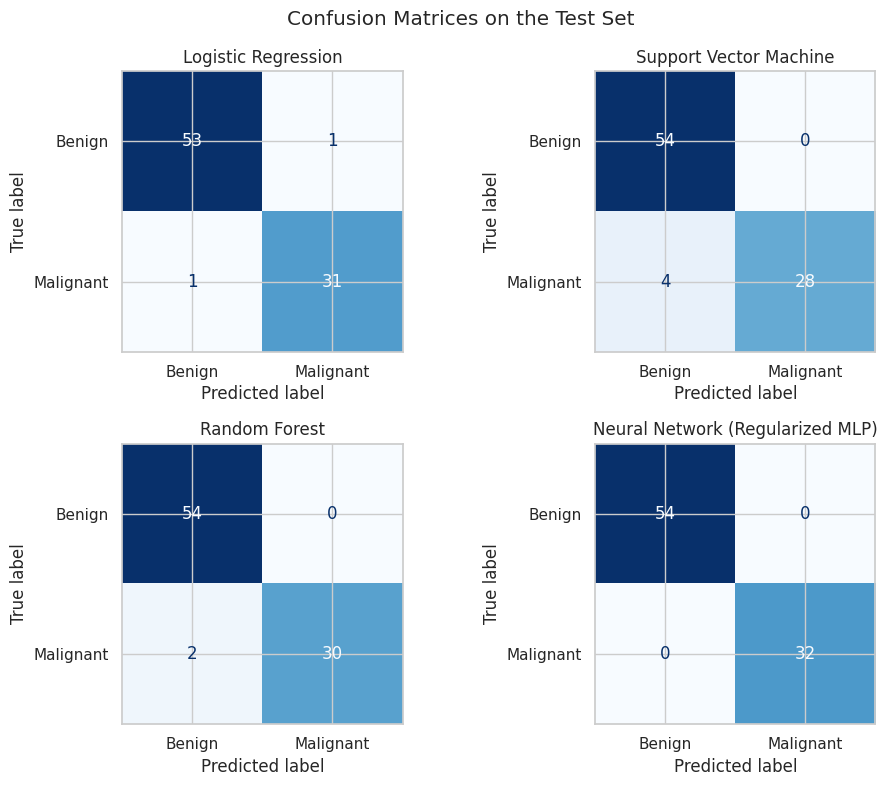

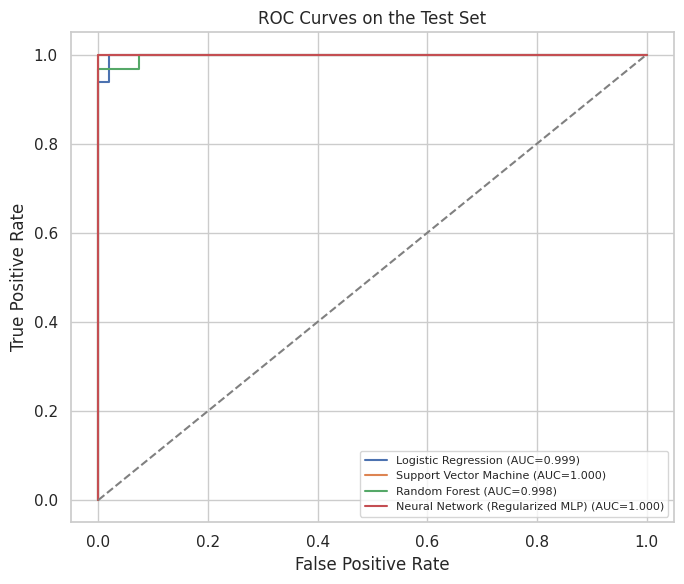

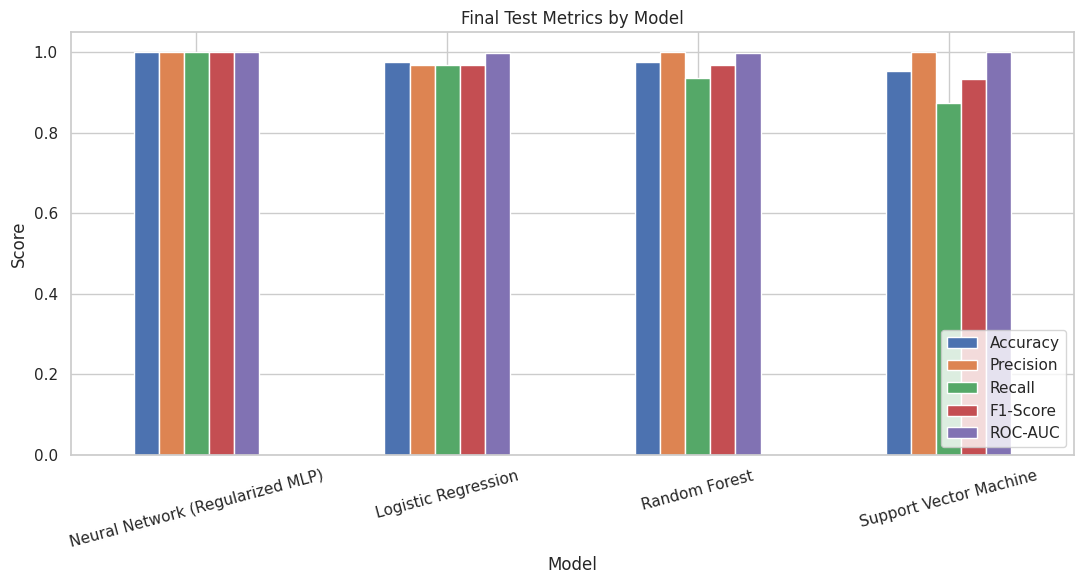


Figures saved to: figures
Result tables saved to: results
Malignant is the positive class (label 1); class predictions use each model's default decision rule (0.50 probability for LR, RF and MLP; decision-function sign for SVM).


In [16]:
# Confusion matrices for all final models.
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, predictions) in zip(axes.flat, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
fig.suptitle("Confusion Matrices on the Test Set")
save_figure(output_dir / "08_test_confusion_matrices.png")

# ROC curves.
plt.figure(figsize=(7, 6))
for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores, pos_label=POSITIVE_LABEL)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves on the Test Set")
plt.legend(fontsize=8)
save_figure(output_dir / "09_test_roc_curves.png")

metric_columns = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
plot_data = test_results.set_index("Model")[metric_columns]
ax = plot_data.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
ax.set_ylabel("Score")
ax.set_title("Final Test Metrics by Model")
ax.tick_params(axis="x", rotation=15)
plt.legend(loc="lower right")
save_figure(output_dir / "10_test_metric_comparison.png")

print(f"\nFigures saved to: {output_dir}")
print(f"Result tables saved to: {tables_dir}")
print("Malignant is the positive class (label 1); class predictions use each model's default decision rule (0.50 probability for LR, RF and MLP; decision-function sign for SVM).")

## Discussion and conclusion

- All four models did very well on the test set (accuracy at least 0.953 and ROC-AUC at least 0.997).
- The regularized Neural Network had the best test results, with no wrong predictions. Logistic Regression was very close (F1 = 0.9688, one false negative) and is easier to interpret.
- Random Forest missed 2 malignant cases and the SVM missed 4 with its default decision rule, even though the SVM has an ROC-AUC of 1.0. Changing the decision threshold may improve its recall.
- The test set is small (86 samples, 32 malignant), so a difference of one or two cases is not large, and a perfect score does not mean the model will be perfect on new patients.
- Future work: tune the decision threshold, test on a larger dataset, use SHAP or LIME to explain the neural network, and try nested cross-validation.